In [25]:
import numpy as np
import rasterio
import rasterio.mask
import geopandas as gpd

In [3]:
boundary = gpd.read_file(r"C:\Users\snvra\NISAR_Data_project\Data\Shapefiles\Malad_MH\Malad_MH.shp")   # <-- change filename

In [4]:
def extract_valid_pixels(tile_path, boundary):
    """
    Clips a tile to the boundary and returns
    all valid pixels as (N_pixels, N_bands).
    """

    with rasterio.open(tile_path) as src:

        # Reproject boundary if required
        if boundary.crs != src.crs:
            boundary = boundary.to_crs(src.crs)

        # Clip
        clipped, _ = rasterio.mask.mask(
            src,
            boundary.geometry,
            crop=True,
            filled=True
        )

        nodata = src.nodata

    # (bands, rows, cols) -> (rows, cols, bands)
    clipped = np.moveaxis(clipped, 0, -1)

    bands = clipped.shape[-1]

    flat = clipped.reshape(-1, bands)

    # Remove invalid pixels
    if nodata is None:
        valid = np.all(np.isfinite(flat), axis=1)
    else:
        valid = (
            np.all(np.isfinite(flat), axis=1) &
            np.any(flat != nodata, axis=1)
        )

    pixels = flat[valid]

    return pixels

In [5]:
tiles = [

r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_0.tif",

r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_1.tif",

r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_2.tif",

r"C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_3.tif"

]

In [6]:
Xt_list = []

for tile in tiles:

    print(f"Processing {tile}")

    pixels = extract_valid_pixels(
        tile,
        boundary
    )

    print("Pixels :", pixels.shape)

    Xt_list.append(pixels)

Processing C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_0.tif
Pixels : (83398, 64)
Processing C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_1.tif
Pixels : (89614, 64)
Processing C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_2.tif
Pixels : (79534, 64)
Processing C:\Users\snvra\NISAR_Data_project\Data\malad_data\Malad_SatEmb_2024_tile_3.tif
Pixels : (85462, 64)


In [7]:
X_target = np.vstack(Xt_list)

print("\nFinal Target Shape")
print(X_target.shape)


Final Target Shape
(338008, 64)


In [8]:
rng = np.random.default_rng(42)

N = min(50000, X_target.shape[0])

idx = rng.choice(X_target.shape[0], N, replace=False)

X_target_sample = X_target[idx]

print(X_target_sample.shape)

(50000, 64)


In [9]:
import geopandas as gpd

krishna_boundary = gpd.read_file(r"C:\Users\snvra\OneDrive\Desktop\Summer_internship_files\krishna_east_div\krishna_east_div.shp")

print(krishna_boundary.columns)

Index(['OBJECTID', 'SHAPE_Leng', 'SHAPE_Area', 'Section', 'geometry'], dtype='object')


In [10]:
import numpy as np
import rasterio
import rasterio.mask
import geopandas as gpd

image_path= r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"
boundary= gpd.read_file(r"C:\Users\snvra\OneDrive\Desktop\Summer_internship_files\krishna_east_div\krishna_east_div.shp")

def extract_pixels_from_boundary(image_path, boundary_path):
    """
    Clip an image using its boundary shapefile and return:
      - valid pixels (N, bands)
      - clipped image (rows, cols, bands)
      - raster profile
      - transform
      - valid mask
    """

    image_path= r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"
    # Read boundary
    boundary = gpd.read_file(r"C:\Users\snvra\OneDrive\Desktop\Summer_internship_files\krishna_east_div\krishna_east_div.shp")

    with rasterio.open(image_path) as src:

        # Match CRS
        if boundary.crs != src.crs:
            boundary = boundary.to_crs(src.crs)

        # Clip raster
        clipped, transform = rasterio.mask.mask(
            src,
            boundary.geometry,
            crop=True,
            filled=True
        )

        profile = src.profile.copy()
        nodata = src.nodata

    # Convert to (rows, cols, bands)
    clipped = np.moveaxis(clipped, 0, -1)

    rows, cols, bands = clipped.shape

    flat = clipped.reshape(-1, bands)

    # Valid pixels
    if nodata is None:
        valid_mask = np.all(np.isfinite(flat), axis=1)
    else:
        valid_mask = (
            np.all(np.isfinite(flat), axis=1) &
            np.any(flat != nodata, axis=1)
        )

    pixels = flat[valid_mask]

    return pixels, clipped, profile, transform, valid_mask 

In [11]:
krishna_image = r"C:\Users\snvra\NISAR_Data_project\Data\krishsatemb2019_24\krishsatemb2024.tif"
krishna_boundary =r"C:\Users\snvra\OneDrive\Desktop\Summer_internship_files\krishna_east_div\krishna_east_div.shp"

X_source, krishna_clip, profile, transform, valid_mask = extract_pixels_from_boundary(
    krishna_image,
    krishna_boundary
)

print("Krishna clipped image:", krishna_clip.shape)
print("Valid pixels:", X_source.shape)

Krishna clipped image: (2069, 1919, 64)
Valid pixels: (1861017, 64)


In [12]:
print("Min:", np.min(X_source))
print("Max:", np.max(X_source))
print("Bands:", X_source.shape[1])

Min: -0.4982698961937717
Max: 0.4982698961937717
Bands: 64


In [37]:
print("Krishna")
print(X_source.shape)
print(X_source.min(), X_source.max())
print(X_source.mean(), X_source.std())

print()

print("Malad")
print(X_target.shape)
print(X_target.min(), X_target.max())
print(X_target.mean(), X_target.std())

Krishna
(1861017, 64)
-0.4982698961937717 0.4982698961937717
0.028436265219606332 0.12173477392571637

Malad
(338008, 64)
-0.42377547097270285 0.4444444444444444
0.0065111546348745565 0.07951485463234555


In [38]:
import numpy as np

rng = np.random.default_rng(42)

Xs = X_source[rng.choice(X_source.shape[0], 50000, replace=False)]
Xt = X_target[rng.choice(X_target.shape[0], 50000, replace=False)]

print(Xs.shape, Xt.shape)

(50000, 64) (50000, 64)


In [39]:
mu_s = Xs.mean(axis=0)
mu_t = Xt.mean(axis=0)

Xs_c = Xs - mu_s
Xt_c = Xt - mu_t

In [40]:
Cs = np.cov(Xs_c, rowvar=False)
Ct = np.cov(Xt_c, rowvar=False)

print(Cs.shape)
print(Ct.shape)

(64, 64)
(64, 64)


In [41]:
eig_s = np.linalg.eigvalsh(Cs)
eig_t = np.linalg.eigvalsh(Ct)

print("Source")
print(eig_s.min(), eig_s.max())

print("Target")
print(eig_t.min(), eig_t.max())

Source
1.1119794228428867e-05 0.21671392898186892
Target
4.200772896696546e-06 0.18856722514708013


In [42]:
ridge = 1e-5

Cs = np.cov(Xs_c, rowvar=False) + ridge * np.eye(64)
Ct = np.cov(Xt_c, rowvar=False) + ridge * np.eye(64)

w_s, V_s = np.linalg.eigh(Cs)
w_t, V_t = np.linalg.eigh(Ct)

w_s = np.clip(w_s, 1e-5, None)
w_t = np.clip(w_t, 1e-5, None)

Cs_inv_half = V_s @ np.diag(1 / np.sqrt(w_s)) @ V_s.T
Ct_half     = V_t @ np.diag(np.sqrt(w_t)) @ V_t.T
A = Cs_inv_half @ Ct_half
Xs_aligned = (Xs - mu_s) @ A + mu_t

In [43]:
print("Source std :", Xs.std())
print("Target std :", Xt.std())
print("Aligned std:", Xs_aligned.std())

print()

print("Source mean :", Xs.mean())
print("Target mean :", Xt.mean())
print("Aligned mean:", Xs_aligned.mean())

Source std : 0.12173104715335359
Target std : 0.07933736348185676
Aligned std: 0.07831909500554324

Source mean : 0.02844707820069204
Target mean : 0.006487863936947329
Aligned mean: 0.006487863936974244


In [44]:
from coral import coral_fit, coral_apply, covariance_gap

params = coral_fit(Xs, Xt)

In [45]:
Xs_aligned = coral_apply(Xs, params)

print("Source std :", Xs.std())
print("Target std :", Xt.std())
print("Aligned std:", Xs_aligned.std())

print("Source mean :", Xs.mean())
print("Target mean :", Xt.mean())
print("Aligned mean:", Xs_aligned.mean())

print("Covariance gap before:",
      covariance_gap(Xs, Xt))

print("Covariance gap after :",
      covariance_gap(Xs_aligned, Xt))

Source std : 0.12173104715335359
Target std : 0.07933736348185676
Aligned std: 0.07921728995450102
Source mean : 0.02844707820069204
Target mean : 0.006487863936947329
Aligned mean: 0.00648786393697678
Covariance gap before: 0.2561644421412486
Covariance gap after : 0.0011762848268682257


In [47]:
from coral import coral_fit, coral_apply

params = coral_fit(Xs, Xt)
rows, cols, bands = krishna_clip.shape

flat = krishna_clip.reshape(-1, bands)

flat_out = flat.copy()

flat_out[valid_mask] = coral_apply(
    flat[valid_mask],
    params
)

krishna_aligned = flat_out.reshape(rows, cols, bands)

In [48]:
aligned_pixels = krishna_aligned.reshape(-1, bands)[valid_mask]

print("Original")
print("Mean:", X_source.mean())
print("Std :", X_source.std())

print()

print("Target")
print("Mean:", X_target.mean())
print("Std :", X_target.std())

print()

print("Aligned")
print("Mean:", aligned_pixels.mean())
print("Std :", aligned_pixels.std())

Original
Mean: 0.028436265219606332
Std : 0.12173477392571637

Target
Mean: 0.0065111546348745565
Std : 0.07951485463234555

Aligned
Mean: 0.006446018582970513
Std : 0.07926066302777078


In [49]:
from coral import covariance_gap

before = covariance_gap(Xs, Xt)
after = covariance_gap(
    coral_apply(Xs, params),
    Xt
)

print("Before :", before)
print("After  :", after)

Before : 0.2561644421412486
After  : 0.0011762848268682257


In [50]:
aligned_pixels = krishna_aligned.reshape(-1, bands)[valid_mask]

print("Original")
print(X_source.mean(), X_source.std())

print("Target")
print(X_target.mean(), X_target.std())

print("Aligned")
print(aligned_pixels.mean(), aligned_pixels.std())

Original
0.028436265219606332 0.12173477392571637
Target
0.0065111546348745565 0.07951485463234555
Aligned
0.006446018582970513 0.07926066302777078


In [51]:
import numpy as np

# Variance using only valid Krishna pixels
var = np.var(X_source, axis=0)

# Top 3 most informative bands
bands = np.argsort(var)[-3:]

print("Selected bands:", bands)
print("Variances:", var[bands])

Selected bands: [31 25 20]
Variances: [0.01750937 0.01953909 0.01982836]


In [52]:
orig_rgb = krishna_clip[:, :, bands]
aligned_rgb = krishna_aligned[:, :, bands]

In [53]:
def stretch(rgb, p2=None, p98=None):

    rgb = rgb.astype(np.float32).copy()

    if p2 is None:
        p2 = np.percentile(rgb.reshape(-1, 3), 2, axis=0)

    if p98 is None:
        p98 = np.percentile(rgb.reshape(-1, 3), 98, axis=0)

    for i in range(3):
        rgb[:, :, i] = np.clip(
            (rgb[:, :, i] - p2[i]) /
            (p98[i] - p2[i] + 1e-8),
            0,
            1,
        )

    return rgb, p2, p98

In [54]:
orig_rgb, p2, p98 = stretch(orig_rgb)

aligned_rgb, _, _ = stretch(
    aligned_rgb,
    p2,
    p98
)

In [55]:
mask = valid_mask.reshape(rows, cols)

orig_rgb[~mask] = 0
aligned_rgb[~mask] = 0

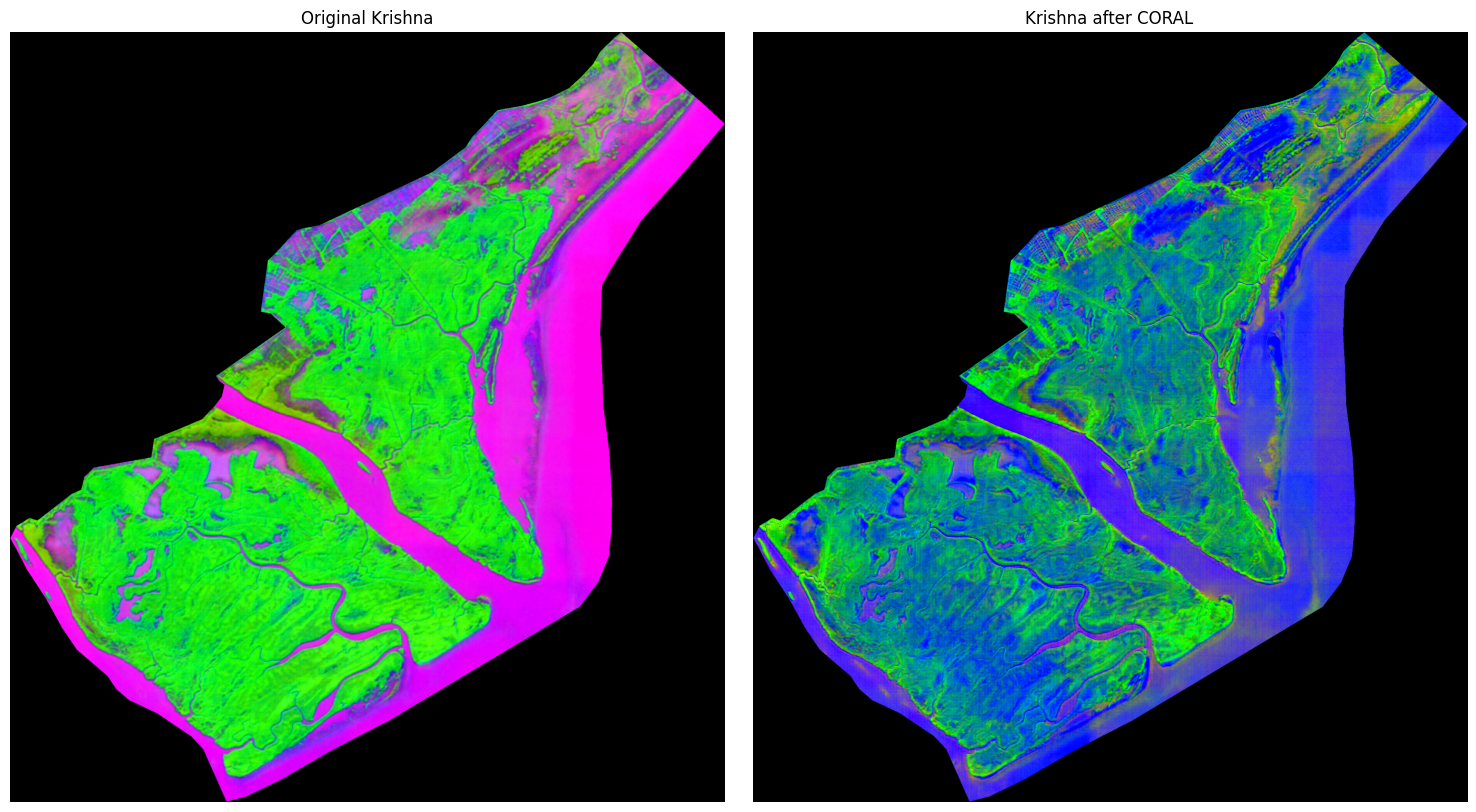

<Figure size 640x480 with 0 Axes>

In [57]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(15, 8))

ax[0].imshow(orig_rgb)
ax[0].set_title("Original Krishna")
ax[0].axis("off")

ax[1].imshow(aligned_rgb)
ax[1].set_title("Krishna after CORAL")
ax[1].axis("off")

plt.tight_layout()
plt.show()
plt.savefig(
    "Krishna_CORAL_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)